### **NAMA : DELA SHINTA SUMOMBA**  
### **NIM : H061241065 (C)**  
### **MATKUL : KECERDASAN ARTIFISIAL**

---

<div align="center">

## **Membuat Prompt AI untuk Permasalahan Geofisika**
</div>

Setiap prompt disusun mengikuti struktur minimum prompt sebagai work specification (Gambar 2.1 pada buku AI Cookbook untuk Earth Sciences):

<div align="center">

![WhatsApp Image 2026-09-29 at 18.54.12.jpeg](<attachment:WhatsApp Image 2026-09-29 at 18.54.12.jpeg>)

</div>
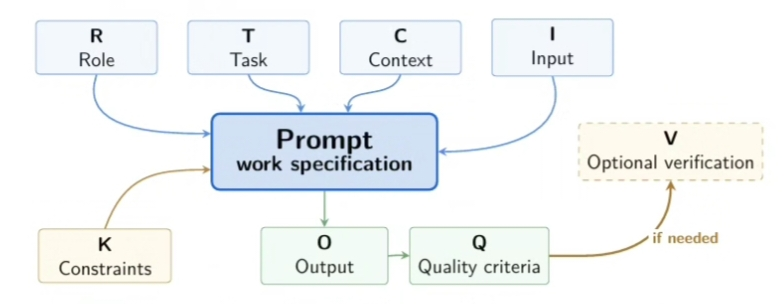

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.special import j1

rng = np.random.default_rng(42)

### **Prompt 1: Interpretasi Geolistrik VES (Schlumberger) untuk Potensi Akuifer**

**Role:** Kamu adalah seorang geofisikawan hidrogeologi yang berpengalaman menginterpretasikan data sounding geolistrik tahanan jenis untuk eksplorasi air tanah.

**Task:** Interpretasikan data Vertical Electrical Sounding (VES) konfigurasi Schlumberger pada satu titik sounding untuk menentukan jumlah lapisan, ketebalan, dan tahanan jenis tiap lapisan, lalu tentukan lapisan mana yang berpotensi menjadi akuifer. Jelaskan alur penalaranmu langkah demi langkah: mulai dari pembacaan kurva resistivitas semu terhadap AB/2, pemodelan inversi 1D, hingga kesimpulan litologi.

**Context:** Lokasi survei berada di wilayah dataran aluvial yang mengalami kesulitan air bersih pada musim kemarau. Tujuan survei adalah menentukan titik dan kedalaman pengeboran sumur. Pengguna adalah mahasiswa yang membutuhkan penjelasan yang dapat dipelajari ulang.

**Input:** Tabel data lapangan berisi nilai AB/2 (m), MN/2 (m), arus I (mA), beda potensial ΔV (mV), dan faktor geometri K. Data ditempel oleh pengguna: [tempel tabel data VES]. Jika data belum tersedia, minta pengguna melengkapinya.

**Constraints:** 
1. Hanya gunakan data yang diberikan; jangan mengarang nilai. 
2. Semua asumsi (misalnya model lapisan horizontal homogen) harus dinyatakan eksplisit. 
3. Bedakan hasil hitungan dari interpretasi geologi. 
4. Jika data tidak cukup atau ada pencilan, katakan dengan jelas dan jangan memaksakan kesimpulan (*failure behavior*). 
5. Jangan membuat klaim kepastian keberadaan air tanah.

**Output:**  
Dua artifact berbentuk narasi: 
1. narasi perhitungan resistivitas semu dan model lapisan (jumlah lapisan, ketebalan, ρ tiap lapisan) yang disajikan dalam tabel teks
2. narasi interpretasi litologi dan rekomendasi kedalaman pengeboran. Rencana output visual (kurva sounding) cukup dideskripsikan dengan kata-kata pada tahap ini.

**Quality criteria:** Setiap lapisan memiliki angka ketebalan dan ρ; setiap kesimpulan litologi disertai alasan berdasarkan rentang nilai resistivitas; asumsi dan ketidakpastian dicantumkan; bahasa Indonesia teknis yang runtut.

**Optional verification:** Hitung ulang satu nilai ρa secara manual dari data mentah dan bandingkan dengan hasilmu; sebutkan jika ada selisih.

PROMPT 1 : VES SCHLUMBERGER - POTENSI AKUIFER

[ARTIFACT 1a] Tabel perhitungan resistivitas semu
 AB/2(m)  MN/2(m)   I(mA)   dV(mV)      K(m)  rho_a(ohm.m)
     1.5      0.2     100   241.55     13.74         33.20
     2.0      0.2     100   127.77     24.74         31.61
     3.0      0.2     100    47.88     56.16         26.89
     5.0      0.5     100    25.45     77.75         19.79
     7.0      0.5     100    11.36    153.15         17.40
    10.0      0.5     100     5.65    313.37         17.71
    15.0      2.5     100    16.37    137.44         22.50
    20.0      2.5     100    11.40    247.40         28.20
    30.0      2.5     200    12.79    561.56         35.91
    50.0      2.5     200     6.20   1566.87         48.57
    70.0      2.5     200     3.81   3074.83         58.58
   100.0      2.5     200     2.14   6279.26         67.19
Tidak ada pencilan menonjol pada uji kehalusan kurva sederhana.

Perbandingan jumlah lapisan (RMS error dalam log10 rho_a):
  2 lapisan 

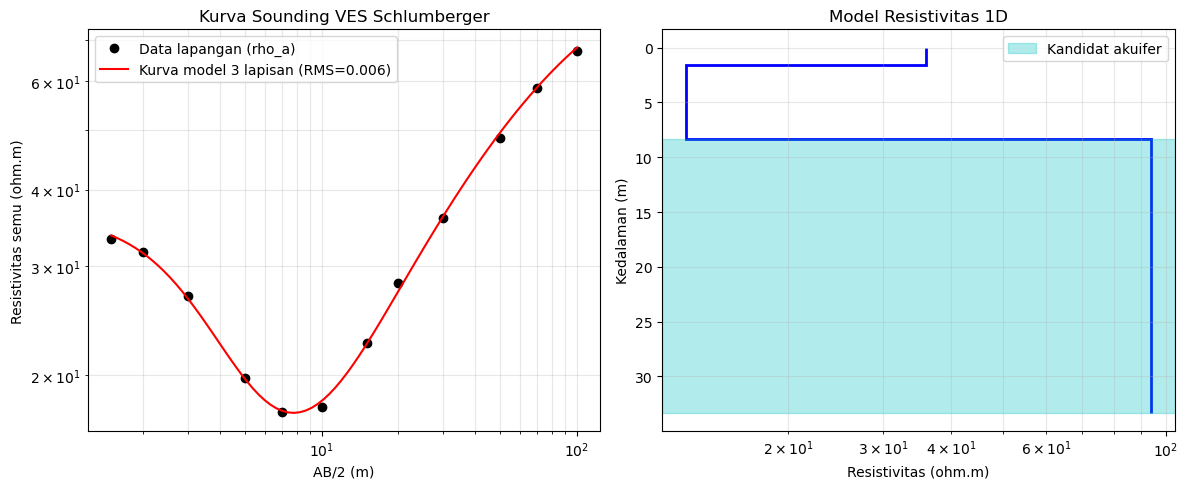

In [2]:
# =====================================================================
# PROMPT 1 : INTERPRETASI GEOLISTRIK VES (SCHLUMBERGER) - POTENSI AKUIFER
# =====================================================================
print("=" * 78)
print("PROMPT 1 : VES SCHLUMBERGER - POTENSI AKUIFER")
print("=" * 78)

# ---------------- INPUT: tabel data lapangan ----------------
AB2 = np.array([1.5, 2, 3, 5, 7, 10, 15, 20, 30, 50, 70, 100])         # AB/2 (m)
MN2 = np.array([0.25, 0.25, 0.25, 0.5, 0.5, 0.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5])  # MN/2 (m)
I_mA = np.array([100, 100, 100, 100, 100, 100, 100, 100, 200, 200, 200, 200], dtype=float)
dV_mV = np.array([241.55, 127.77, 47.88, 25.45, 11.36, 5.65,
                  16.37, 11.40, 12.79, 6.20, 3.81, 2.14])               # beda potensial (mV)

# ---------------- Cek kelengkapan data (failure behavior) ----------------
n = len(AB2)
if n < 8:
    print("PERINGATAN: jumlah titik < 8, model lapisan tidak dapat ditentukan andal.")
if not (len(MN2) == n and len(I_mA) == n and len(dV_mV) == n):
    raise SystemExit("Data tidak lengkap: panjang kolom tidak sama. Lengkapi data dahulu.")
if np.any(MN2 / AB2 > 0.2):
    print("PERINGATAN: ada titik dengan MN/AB-2 > 0,2; pendekatan Schlumberger kurang valid.")

# ---------------- Langkah 1: faktor geometri & resistivitas semu ----------------
# K = pi (L^2 - l^2) / (2 l)  ;  rho_a = K * dV / I   (L = AB/2, l = MN/2)
K = np.pi * (AB2**2 - MN2**2) / (2 * MN2)
rho_a = K * dV_mV / I_mA                      # mV/mA = ohm -> ohm.m

# Deteksi pencilan: simpangan log rho_a terhadap rata-rata tetangga
logra = np.log10(rho_a)
pencilan = []
for i in range(1, n - 1):
    if abs(logra[i] - 0.5 * (logra[i - 1] + logra[i + 1])) > 0.08:
        pencilan.append(i)

print("\n[ARTIFACT 1a] Tabel perhitungan resistivitas semu")
print(f"{'AB/2(m)':>8} {'MN/2(m)':>8} {'I(mA)':>7} {'dV(mV)':>8} {'K(m)':>9} {'rho_a(ohm.m)':>13}")
for i in range(n):
    print(f"{AB2[i]:8.1f} {MN2[i]:8.1f} {I_mA[i]:7.0f} {dV_mV[i]:8.2f} {K[i]:9.2f} {rho_a[i]:13.2f}")
if pencilan:
    print("Titik terindikasi pencilan (indeks ke-):", pencilan, "-> periksa data lapangan.")
else:
    print("Tidak ada pencilan menonjol pada uji kehalusan kurva sederhana.")

# ---------------- Langkah 2: inversi 1D (model lapisan horizontal homogen) ----------------
# Forward: rho_a(L) = rho_1 + L^2 * Int[(T(lam)-rho_1) J1(lam L) lam dlam]
# T(lam) dihitung dengan rekursi Pekeris dari lapisan paling bawah.
lam = np.arange(0.002, 30, 0.004)
dlam = 0.004
W = j1(lam[:, None] * AB2[None, :]) * lam[:, None] * dlam     # matriks bobot (tetap)

hasil_model = {}
for nlay in [2, 3, 4]:
    best_cost = 1e9
    best_p = None
    npar = nlay + (nlay - 1)
    lo = np.array([0.0] * nlay + [-0.3] * (nlay - 1))      # log10 rho (1 ohm.m) , log10 h (0,5 m)
    hi = np.array([3.5] * nlay + [1.7] * (nlay - 1))       # 3162 ohm.m , 50 m
    Nrestart = 6 * (nlay - 1)                              # beberapa percobaan ulang acak
    Niter = 1200
    for rs in range(Nrestart):
        loc_cost = 1e9
        loc_p = None
        for it in range(Niter):
            if it < Niter // 3 or loc_p is None:
                p = lo + (hi - lo) * rng.random(npar)                  # pencarian acak
            else:
                sigma = 0.3 * (1 - it / Niter) + 0.005                 # perhalus lokal
                p = np.clip(loc_p + rng.normal(0, sigma, npar), lo, hi)
            rho_m = 10 ** p[:nlay]
            h_m = 10 ** p[nlay:]
            T = np.full_like(lam, rho_m[-1])
            for k in range(nlay - 2, -1, -1):
                th = np.tanh(lam * h_m[k])
                T = (T + rho_m[k] * th) / (1 + T * th / rho_m[k])
            ra_model = rho_m[0] + AB2**2 * ((T - rho_m[0]) @ W)
            cost = np.sqrt(np.mean((np.log10(ra_model) - logra) ** 2))
            if cost < loc_cost:
                loc_cost, loc_p = cost, p.copy()
        if loc_cost < best_cost:
            best_cost, best_p = loc_cost, loc_p.copy()
    hasil_model[nlay] = (best_cost, best_p)

print("\nPerbandingan jumlah lapisan (RMS error dalam log10 rho_a):")
for nlay in [2, 3, 4]:
    print(f"  {nlay} lapisan : RMS = {hasil_model[nlay][0]:.4f}  (~{(10**hasil_model[nlay][0]-1)*100:.1f} %)")

# Pilih model paling sederhana yang RMS-nya tidak jauh lebih buruk dari terbaik
rms_min = min(v[0] for v in hasil_model.values())
nlay_pilih = 4
for nlay in [2, 3, 4]:
    if hasil_model[nlay][0] <= rms_min * 1.3 + 0.005:
        nlay_pilih = nlay
        break
rms_pilih, p_pilih = hasil_model[nlay_pilih]
rho_lap = 10 ** p_pilih[:nlay_pilih]
h_lap = 10 ** p_pilih[nlay_pilih:]

# ---------------- Langkah 3: interpretasi litologi berdasar rentang resistivitas ----------------
z_atas = np.concatenate([[0], np.cumsum(h_lap)])
print(f"\n[ARTIFACT 1b] Model lapisan terpilih ({nlay_pilih} lapisan, RMS = {rms_pilih:.4f})")
print(f"{'Lapisan':>8} {'rho(ohm.m)':>11} {'tebal(m)':>9} {'kedalaman(m)':>16}  Dugaan litologi")
akuifer = []
for k in range(nlay_pilih):
    r = rho_lap[k]
    if r < 10:
        lit = "lempung/lanau jenuh (air payau?)"
    elif r < 30:
        lit = "lempung / lanau (penghalang air, akuitar)"
    elif r < 200 and z_atas[k] > 0:
        lit = "pasir/pasir lempungan - kandidat akuifer"
        akuifer.append(k)
    elif r < 200:
        lit = "tanah penutup/zona tak jenuh (bukan target)"
    else:
        lit = "kerikil/pasir kering atau batuan keras"
    if k < nlay_pilih - 1:
        tebal = f"{h_lap[k]:9.2f}"
        dep = f"{z_atas[k]:6.2f} - {z_atas[k+1]:6.2f}"
    else:
        tebal = f"{'tak hingga':>9}"
        dep = f"{z_atas[k]:6.2f} - ..."
    print(f"{k+1:8d} {r:11.1f} {tebal} {dep:>16}  {lit}")

print("\n[Narasi interpretasi]")
print("Asumsi: lapisan horizontal, homogen, isotrop; MN << AB (Schlumberger ideal).")
if akuifer:
    for k in akuifer:
        if k < nlay_pilih - 1:
            print(f"- Lapisan {k+1} (rho = {rho_lap[k]:.0f} ohm.m) pada kedalaman {z_atas[k]:.1f}-{z_atas[k+1]:.1f} m "
                  f"berpotensi akuifer berdasarkan rentang resistivitas pasir jenuh.")
        else:
            print(f"- Lapisan {k+1} (rho = {rho_lap[k]:.0f} ohm.m) mulai kedalaman {z_atas[k]:.1f} m berpotensi akuifer; "
                  f"ketebalan tidak terdefinisi (lapisan terakhir).")
    k0 = akuifer[0]
    if k0 < nlay_pilih - 1:
        z_bor = z_atas[k0 + 1]
    else:
        z_bor = z_atas[k0] + 15          # lapisan terakhir: ketebalan tak diketahui, diambil +15 m (asumsi)
    print(f"- Rekomendasi awal: pengeboran uji sampai +- {z_bor:.0f} m, dengan verifikasi log bor/uji pompa.")
else:
    print("- Tidak ada lapisan dalam rentang resistivitas akuifer; jangan memaksakan kesimpulan.")
print("Ketidakpastian: inversi non-unik (ekuivalensi rho-h), rentang litologi bersifat indikatif,")
print("dan keberadaan air tanah TIDAK dapat dipastikan hanya dari data resistivitas.")

# ---------------- Verifikasi: hitung manual satu titik ----------------
iv = 4
print(f"\n[Verifikasi manual titik ke-{iv+1}]")
K_manual = np.pi * (AB2[iv]**2 - MN2[iv]**2) / (2 * MN2[iv])
ra_manual = K_manual * dV_mV[iv] / I_mA[iv]
print(f"K = pi*({AB2[iv]}^2 - {MN2[iv]}^2)/(2*{MN2[iv]}) = {K_manual:.3f} m")
print(f"rho_a = K*dV/I = {K_manual:.3f}*{dV_mV[iv]}/{I_mA[iv]:.0f} = {ra_manual:.3f} ohm.m")
print(f"Hasil program = {rho_a[iv]:.3f} ohm.m ; selisih = {abs(ra_manual - rho_a[iv]):.2e}")

# ---------------- Grafik: kurva sounding & model 1D ----------------
Ld = np.logspace(np.log10(AB2.min()), np.log10(AB2.max()), 80)
Wd = j1(lam[:, None] * Ld[None, :]) * lam[:, None] * dlam
T = np.full_like(lam, rho_lap[-1])
for k in range(nlay_pilih - 2, -1, -1):
    th = np.tanh(lam * h_lap[k])
    T = (T + rho_lap[k] * th) / (1 + T * th / rho_lap[k])
ra_kurva = rho_lap[0] + Ld**2 * ((T - rho_lap[0]) @ Wd)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].loglog(AB2, rho_a, "ko", label="Data lapangan (rho_a)")
ax[0].loglog(Ld, ra_kurva, "r-", label=f"Kurva model {nlay_pilih} lapisan (RMS={rms_pilih:.3f})")
ax[0].set_xlabel("AB/2 (m)")
ax[0].set_ylabel("Resistivitas semu (ohm.m)")
ax[0].set_title("Kurva Sounding VES Schlumberger")
ax[0].grid(True, which="both", alpha=0.3)
ax[0].legend()

edges = np.concatenate([z_atas, [z_atas[-1] + 25]])          # lapisan terakhir digambar 25 m
ax[1].stairs(rho_lap, edges, orientation="horizontal", baseline=None, color="b", lw=2)
for k in akuifer:
    ax[1].axhspan(edges[k], edges[k + 1], color="c", alpha=0.3, label="Kandidat akuifer" if k == akuifer[0] else None)
ax[1].set_xscale("log")
ax[1].invert_yaxis()
ax[1].set_xlabel("Resistivitas (ohm.m)")
ax[1].set_ylabel("Kedalaman (m)")
ax[1].set_title("Model Resistivitas 1D")
ax[1].grid(True, which="both", alpha=0.3)
if akuifer:
    ax[1].legend()
plt.tight_layout()
plt.show()

#### **Interpretasi Prompt 1**
Kurva sounding berbentuk tipe-H (turun ke minimum lalu naik lagi). Inversi 1D membandingkan 2, 3, dan 4 lapisan; model 3 lapisan paling sederhana yang cocok dengan data (RMS ≈ 1,5 %), sedangkan 2 lapisan jelas kurang (RMS ≈ 22 %).

Model: lapisan 1 (±36 Ω·m, ±1,6 m) dibaca sebagai tanah penutup tak jenuh; lapisan 2 (±13 Ω·m, ±6,7 m) bernilai rendah sehingga diduga lempung/lanau (akuitar); lapisan 3 (±94 Ω·m, mulai ±8,3 m) berada pada rentang pasir jenuh sehingga menjadi kandidat akuifer. Resistivitas rendah tidak otomatis berarti air, dan inversi bersifat non-unik, sehingga keberadaan air tanah harus dikonfirmasi dengan pengeboran uji.

---

### **Prompt 2: Geolistrik 2D (ERT, Wenner-Schlumberger) untuk Bidang Gelincir Longsor**

**Role:** Kamu adalah seorang geofisikawan geoteknik yang ahli dalam interpretasi Electrical Resistivity Tomography (ERT) untuk mitigasi bencana longsor.

**Task:** Analisis penampang resistivitas 2D hasil inversi ERT untuk mengidentifikasi zona lapuk, zona jenuh air, dan kemungkinan bidang gelincir pada lereng. Buat narasi yang menjelaskan kontras resistivitas antarzona, mengaitkannya dengan kondisi litologi dan kandungan air, lalu menilai zona mana yang paling berisiko.

**Context:** Lereng berada di daerah perbukitan dengan curah hujan tinggi dan pernah terjadi retakan tanah. Hasil analisis akan menjadi bahan diskusi awal untuk rekomendasi survei lanjutan, bukan keputusan teknik final.

**Input:** Deskripsi atau tabel nilai resistivitas hasil inversi (misalnya dari Res2DInv) beserta panjang lintasan, spasi elektroda, dan nilai RMS error: [tempel deskripsi/tabel penampang].

**Constraints:** 
1. Sebutkan bahwa interpretasi ERT bersifat non-unik dan dipengaruhi resolusi menurun terhadap kedalaman. 
2. Jangan menyimpulkan kestabilan lereng hanya dari resistivitas. 
3. Gunakan hanya data yang diberikan. 
4. Jika RMS error tinggi atau data tidak lengkap, nyatakan keterbatasannya di awal jawaban.

**Output:**  
Dua artifact narasi: 
1. ringkasan zonasi resistivitas (rentang nilai, kedalaman, dugaan material) dalam tabel teks
2. narasi penilaian risiko dan usulan survei pendukung (misalnya bor tangan, seismik refraksi). Rencana gambar penampang hanya dideskripsikan dengan kalimat.

**Quality criteria:** Zona dibedakan secara kuantitatif; kaitan resistivitas–litologi–air dijelaskan logis; keterbatasan metode disebutkan; usulan tindak lanjut relevan dan spesifik.

**Optional verification:** Sajikan satu penjelasan alternatif untuk zona resistivitas rendah (misalnya lempung vs. jenuh air) dan jelaskan data apa yang dapat membedakannya.



PROMPT 2 : ERT 2D - ZONA LAPUK, JENUH AIR, & BIDANG GELINCIR

[KETERBATASAN - dibaca terlebih dahulu]
- Interpretasi ERT bersifat non-unik; resolusi menurun terhadap kedalaman.
- Resistivitas saja TIDAK cukup untuk menyimpulkan kestabilan lereng.
- RMS error 7.8 % sedang (5-10 %): gunakan dengan hati-hati.
- Baris model terdalam (13.4 m) melebihi perkiraan kedalaman investigasi (~12 m): nilai di bawahnya kurang terkontrol data.

[ARTIFACT 2a] Ringkasan zonasi resistivitas
Zona                              rho min-max   kedalaman(m)         x(m)  Dugaan material
Z1: sangat rendah (<40)            14-38        4.3-8.2        20-35       lempung / material jenuh air (kandidat zona jenuh)
Z2: rendah-sedang (40-150)         40-140       1.5-10.6        5-40       tanah/batuan lapuk lembap
Z3: sedang-tinggi (150-400)       150-380       0.5-10.6        5-55       tanah lapuk kering / batuan lapuk
Z4: tinggi (>400)                 450-1100      6.1-13.4        5-55       batuan segar / dasar

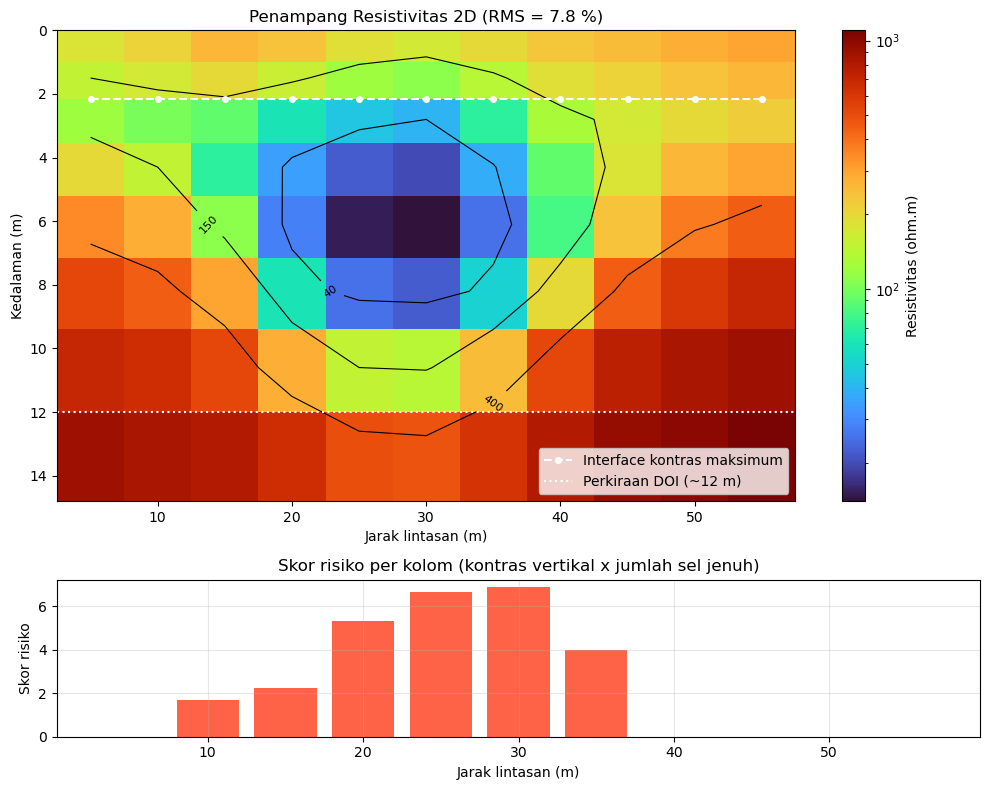

In [3]:
# =====================================================================
# PROMPT 2 : ERT 2D (WENNER-SCHLUMBERGER) - BIDANG GELINCIR LONGSOR
# =====================================================================
print("\n" + "=" * 78)
print("PROMPT 2 : ERT 2D - ZONA LAPUK, JENUH AIR, & BIDANG GELINCIR")
print("=" * 78)

# ---------------- INPUT: hasil inversi (misal dari Res2DInv) ----------------
panjang_lintasan = 60.0      # m
spasi_elektroda = 5.0        # m
rms_error = 7.8              # %
x_pos = np.arange(5, 60, 5.0)                                         # 11 kolom (m)
z_pos = np.array([0.5, 1.5, 2.8, 4.3, 6.1, 8.2, 10.6, 13.4])          # kedalaman tengah sel (m)
rho_2d = np.array([
    [180, 210, 260, 240, 190, 170, 200, 230, 250, 280, 300],
    [150, 170, 200, 160, 120, 110, 140, 190, 210, 240, 260],
    [120, 100,  90,  60,  45,  40,  70, 130, 170, 200, 220],
    [200, 150,  70,  35,  22,  20,  38,  90, 180, 260, 300],
    [350, 280, 110,  28,  15,  14,  25,  80, 240, 380, 450],
    [520, 450, 300,  60,  25,  22,  50, 200, 450, 600, 700],
    [700, 650, 520, 280, 150, 140, 250, 520, 750, 850, 900],
    [900, 850, 800, 650, 500, 480, 620, 800, 950, 1000, 1100]], dtype=float)

# ---------------- Keterbatasan (disebut di awal jawaban) ----------------
print("\n[KETERBATASAN - dibaca terlebih dahulu]")
print("- Interpretasi ERT bersifat non-unik; resolusi menurun terhadap kedalaman.")
print("- Resistivitas saja TIDAK cukup untuk menyimpulkan kestabilan lereng.")
if rms_error > 10:
    print(f"- RMS error {rms_error:.1f} % TINGGI (> 10 %): hasil inversi kurang andal.")
elif rms_error > 5:
    print(f"- RMS error {rms_error:.1f} % sedang (5-10 %): gunakan dengan hati-hati.")
else:
    print(f"- RMS error {rms_error:.1f} % cukup baik (< 5 %).")
doi = 0.2 * panjang_lintasan          # aturan praktis kedalaman investigasi
if z_pos.max() > doi:
    print(f"- Baris model terdalam ({z_pos.max():.1f} m) melebihi perkiraan kedalaman investigasi "
          f"(~{doi:.0f} m): nilai di bawahnya kurang terkontrol data.")

# ---------------- Zonasi kuantitatif ----------------
batas = [0, 40, 150, 400, 1e9]
nama_zona = ["Z1: sangat rendah (<40)", "Z2: rendah-sedang (40-150)",
             "Z3: sedang-tinggi (150-400)", "Z4: tinggi (>400)"]
dugaan = ["lempung / material jenuh air (kandidat zona jenuh)",
          "tanah/batuan lapuk lembap",
          "tanah lapuk kering / batuan lapuk",
          "batuan segar / dasar kompak"]
print("\n[ARTIFACT 2a] Ringkasan zonasi resistivitas")
print(f"{'Zona':<30} {'rho min-max':>14} {'kedalaman(m)':>14} {'x(m)':>12}  Dugaan material")
for zi in range(4):
    mask = (rho_2d >= batas[zi]) & (rho_2d < batas[zi + 1])
    if mask.sum() == 0:
        continue
    iz, ix = np.where(mask)
    print(f"{nama_zona[zi]:<30} {rho_2d[mask].min():6.0f}-{rho_2d[mask].max():<7.0f} "
          f"{z_pos[iz].min():5.1f}-{z_pos[iz].max():<8.1f} {x_pos[ix].min():4.0f}-{x_pos[ix].max():<7.0f}  {dugaan[zi]}")

# ---------------- Bidang gelincir potensial: kontras resistif (atas) -> konduktif (bawah) ----------------
print("\n[ARTIFACT 2b] Penilaian risiko per kolom (kontras resistivitas vertikal)")
print(f"{'x(m)':>6} {'z interface(m)':>15} {'rho atas':>9} {'rho bawah':>10} {'kontras':>8} {'skor':>6}")
skor = np.zeros(len(x_pos))
z_if = np.zeros(len(x_pos))
for ix in range(len(x_pos)):
    kontras_maks = 1.0
    idx_maks = 0
    for iz in range(len(z_pos) - 1):
        kontras = rho_2d[iz, ix] / rho_2d[iz + 1, ix]       # >1 jika menurun terhadap kedalaman
        if kontras > kontras_maks:
            kontras_maks, idx_maks = kontras, iz
    z_if[ix] = 0.5 * (z_pos[idx_maks] + z_pos[idx_maks + 1])
    jenuh = np.sum(rho_2d[:, ix] < 40)                      # jumlah sel jenuh pada kolom
    skor[ix] = kontras_maks * (1 + 0.5 * jenuh) if kontras_maks > 1.5 else 0.0
    print(f"{x_pos[ix]:6.0f} {z_if[ix]:15.1f} {rho_2d[idx_maks, ix]:9.0f} {rho_2d[idx_maks+1, ix]:10.0f} "
          f"{kontras_maks:8.2f} {skor[ix]:6.2f}")

urut = np.argsort(skor)[::-1]
print("\n[Narasi penilaian risiko]")
if skor[urut[0]] > 0:
    print(f"- Zona paling berisiko: x = {x_pos[urut[0]]:.0f} m dan {x_pos[urut[1]]:.0f} m, "
          f"interface resistif-di-atas-konduktif pada kedalaman +- {z_if[urut[0]]:.1f} m.")
    print("  Pola ini konsisten dengan lapisan lapuk/kering di atas zona lempung atau jenuh air,")
    print("  yang secara konseptual dapat menjadi kandidat bidang gelincir (perlu verifikasi).")
else:
    print("- Tidak ada kontras vertikal yang menonjol; tidak ada kandidat bidang gelincir jelas.")
print("- Usulan survei lanjutan: (1) bor tangan/hand auger di titik x tersebut untuk cek lempung & muka air;")
print("  (2) seismik refraksi untuk kecepatan Vp batas lapuk-segar; (3) pengukuran IP atau ERT berulang")
print("  musim hujan vs kemarau; (4) pemasangan inclinometer/piezometer.")

print("\n[Verifikasi: penjelasan alternatif zona resistivitas rendah]")
print("Zona rho < 40 ohm.m dapat berupa (a) batuan/tanah jenuh air, atau (b) lempung kering-lembap.")
print("Pembeda: data bor (tekstur, kadar air), IP/chargeability (lempung tinggi), serta ERT time-lapse")
print("(zona jenuh berubah resistivitasnya mengikuti hujan, lempung relatif tetap).")

# ---------------- Grafik: penampang resistivitas 2D & skor risiko ----------------
fig, ax = plt.subplots(2, 1, figsize=(10, 8), gridspec_kw={"height_ratios": [3, 1]})
pm = ax[0].pcolormesh(x_pos, z_pos, rho_2d, shading="nearest", cmap="turbo",
                      norm=LogNorm(vmin=rho_2d.min(), vmax=rho_2d.max()))
plt.colorbar(pm, ax=ax[0], label="Resistivitas (ohm.m)")
cs = ax[0].contour(x_pos, z_pos, rho_2d, levels=[40, 150, 400], colors="k", linewidths=0.8)
ax[0].clabel(cs, fmt="%d", fontsize=8)
ax[0].plot(x_pos, z_if, "w--o", ms=4, label="Interface kontras maksimum")
ax[0].axhline(doi, color="white", ls=":", label=f"Perkiraan DOI (~{doi:.0f} m)")
ax[0].invert_yaxis()
ax[0].set_xlabel("Jarak lintasan (m)")
ax[0].set_ylabel("Kedalaman (m)")
ax[0].set_title(f"Penampang Resistivitas 2D (RMS = {rms_error} %)")
ax[0].legend(loc="lower right")

ax[1].bar(x_pos, skor, width=4, color=np.where(skor > 0, "tomato", "lightgray"))
ax[1].set_xlabel("Jarak lintasan (m)")
ax[1].set_ylabel("Skor risiko")
ax[1].set_title("Skor risiko per kolom (kontras vertikal x jumlah sel jenuh)")
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### **Interpretasi Prompt 2**
Penampang memperlihatkan inti resistivitas rendah (±14–40 Ω·m) pada x ≈ 20–35 m dan kedalaman ±4–9 m, dikelilingi material lapuk (±40–400 Ω·m) dan batuan resisten (>400 Ω·m) di bagian bawah dan tepi. Kontras vertikal terbesar terdapat di sekitar x = 25–30 m, sehingga zona ini diberi skor risiko tertinggi sebagai kandidat bidang gelincir.

RMS 7,8 % tergolong sedang, dan baris model terdalam melewati perkiraan DOI (~12 m). Zona rendah dapat berupa lempung atau material jenuh air; pembedanya perlu bor tangan, IP, atau ERT berulang. Resistivitas saja tidak cukup untuk menyimpulkan kestabilan lereng.

---

### **Prompt 3: Seismik Refraksi untuk Kedalaman Batuan Dasar**

**Role:** Kamu adalah seorang geofisikawan seismik dangkal yang berpengalaman dalam interpretasi data seismik refraksi untuk keperluan rekayasa fondasi.

**Task:** Tentukan kecepatan gelombang P dan ketebalan tiap lapisan, serta kedalaman batuan dasar, dari kurva waktu tempuh (*travel time*) seismik refraksi. Jelaskan cara membaca titik patah (*crossover distance*), menghitung kecepatan dari kemiringan garis, dan menurunkan ketebalan lapisan.

**Context:** Survei dilakukan pada lokasi rencana bangunan untuk memperkirakan kedalaman fondasi. Pengguna belajar metode ini, sehingga langkah perhitungan harus terlihat.

**Input:** Tabel jarak geophone (m) dan waktu tiba gelombang P (ms) untuk *forward* dan *reverse shot*: [tempel data waktu tempuh].

**Constraints:** 
1. Asumsikan lapisan datar dan kecepatan meningkat terhadap kedalaman, dan nyatakan asumsi ini. 
2. Tunjukkan rumus yang dipakai dan satuan setiap variabel. 
3. Jangan membulatkan berlebihan; laporkan hasil dengan angka signifikan yang wajar. 
4. Bila data forward dan reverse tidak konsisten, jelaskan kemungkinan penyebab (kemiringan lapisan, kesalahan picking) dan jangan menggabungkannya secara paksa.

**Output:**  
Dua artifact narasi: 
1. rincian perhitungan kecepatan dan ketebalan lapisan dalam tabel teks
2. narasi kesimpulan kedalaman batuan dasar dan implikasinya terhadap fondasi. Grafik travel time dideskripsikan secara naratif saja.

**Quality criteria:** Rumus benar dan konsisten; semua angka dapat ditelusuri ke data input; asumsi dan sumber ketidakpastian tercantum; kesimpulan tidak melebihi bukti.

**Optional verification:** Cek silang ketebalan lapisan pertama menggunakan dua rumus berbeda (crossover distance dan intercept time) dan laporkan perbedaannya.


PROMPT 3 : SEISMIK REFRAKSI - KEDALAMAN BATUAN DASAR

Asumsi: lapisan datar/sedikit miring, kecepatan naik terhadap kedalaman (tidak ada lapisan tersembunyi).
Rumus: v = 1000/slope [m/s] (slope dalam ms/m); ti = intersep [ms];
       h1 = ti2*v1*v2 / (2*sqrt(v2^2 - v1^2)) ;
       h2 = (ti3 - 2*h1*sqrt(v3^2 - v1^2)/(v1*v3)) * v2*v3 / (2*sqrt(v3^2 - v2^2))  (ti dalam detik)

[ARTIFACT 3a] Rincian perhitungan kecepatan dan ketebalan

  Shot forward:
   Lapisan   Vp (m/s)  intersep (ms)
         1        400          -0.10
         2       1271          19.46
         3       2984          31.77
  h1 = 4.10 m ; h2 = 8.05 m ; kedalaman batuan dasar = 12.15 m

  Shot reverse:
   Lapisan   Vp (m/s)  intersep (ms)
         1        411           0.60
         2       1190          18.80
         3       3016          32.06
  h1 = 4.12 m ; h2 = 7.91 m ; kedalaman batuan dasar = 12.03 m

[Uji konsistensi forward vs reverse]
  V1: forward     400 | reverse     411 | beda   2.7 %
  V2: forward  

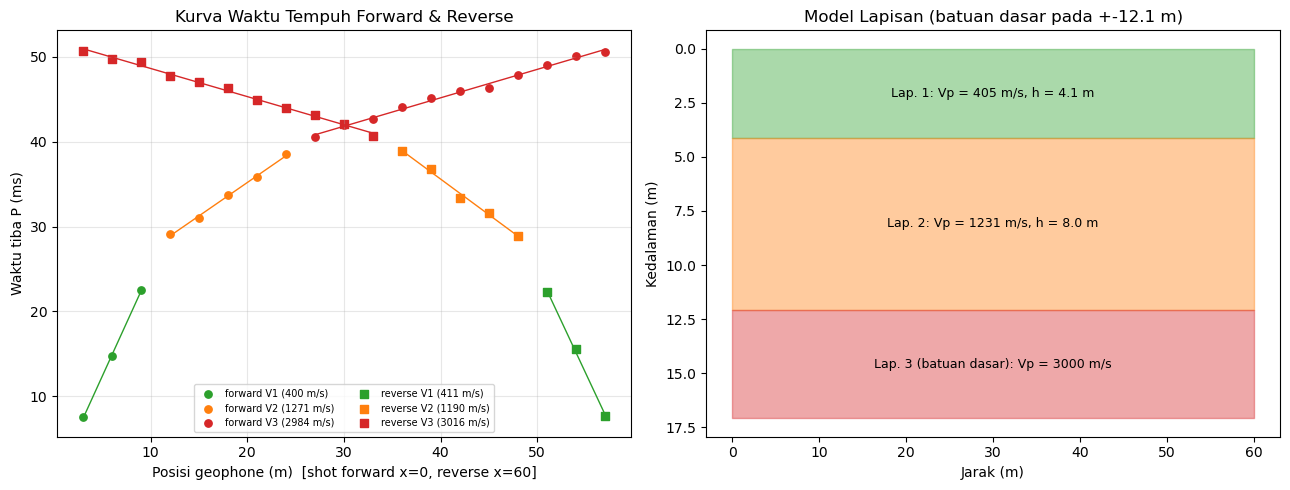

In [4]:
# =====================================================================
# PROMPT 3 : SEISMIK REFRAKSI - KEDALAMAN BATUAN DASAR
# =====================================================================
print("\n" + "=" * 78)
print("PROMPT 3 : SEISMIK REFRAKSI - KEDALAMAN BATUAN DASAR")
print("=" * 78)

# ---------------- INPUT: travel time forward & reverse shot ----------------
panjang_bentang = 60.0                                               # m (shot forward di x=0, reverse di x=60)
x_geo = np.arange(3, 58, 3.0)                                        # posisi geophone (m)
t_fwd = np.array([7.5, 14.7, 22.5, 29.1, 31.0, 33.7, 35.8, 38.5, 40.5, 42.0,
                  42.7, 44.1, 45.1, 46.0, 46.3, 47.9, 49.0, 50.1, 50.6])   # ms
t_rev = np.array([50.7, 49.8, 49.4, 47.8, 47.0, 46.3, 44.9, 44.0, 43.1, 42.1,
                  40.7, 38.9, 36.8, 33.4, 31.6, 28.9, 22.3, 15.6, 7.7])    # ms, geophone x=3..57
# pembagian segmen (hasil picking titik patah oleh pengguna), indeks pada array urut jarak naik
seg = {"V1": (0, 3), "V2": (3, 8), "V3": (8, 19)}                     # [awal, akhir)

# Reverse: jarak dari shot reverse, diurutkan naik
r_geo = panjang_bentang - x_geo
urut_r = np.argsort(r_geo)
data = {"forward": (x_geo, t_fwd), "reverse": (r_geo[urut_r], t_rev[urut_r])}

print("\nAsumsi: lapisan datar/sedikit miring, kecepatan naik terhadap kedalaman (tidak ada lapisan tersembunyi).")
print("Rumus: v = 1000/slope [m/s] (slope dalam ms/m); ti = intersep [ms];")
print("       h1 = ti2*v1*v2 / (2*sqrt(v2^2 - v1^2)) ;")
print("       h2 = (ti3 - 2*h1*sqrt(v3^2 - v1^2)/(v1*v3)) * v2*v3 / (2*sqrt(v3^2 - v2^2))  (ti dalam detik)")

hasil = {}
fits = {}
print("\n[ARTIFACT 3a] Rincian perhitungan kecepatan dan ketebalan")
for nama, (xs, ts) in data.items():
    v = []
    ti = []
    fits[nama] = {}
    for kunci in ["V1", "V2", "V3"]:
        a, b = seg[kunci]
        slope, intercept = np.polyfit(xs[a:b], ts[a:b], 1)       # t = slope*x + intercept (ms)
        v.append(1000.0 / slope)
        fits[nama][kunci] = (slope, intercept)
        ti.append(intercept)
    v1_, v2_, v3_ = v
    ti2, ti3 = ti[1] / 1000, ti[2] / 1000                         # ke detik
    h1_ = ti2 * v1_ * v2_ / (2 * np.sqrt(v2_**2 - v1_**2))
    h2_ = (ti3 - 2 * h1_ * np.sqrt(v3_**2 - v1_**2) / (v1_ * v3_)) * v2_ * v3_ / (2 * np.sqrt(v3_**2 - v2_**2))
    # cek silang h1 dengan crossover distance
    xc = ti[1] / (1000 / v1_ - 1000 / v2_)                         # (ms)/(ms/m) = m
    h1_xc = 0.5 * xc * np.sqrt((v2_ - v1_) / (v2_ + v1_))
    hasil[nama] = dict(v=v, ti=ti, h1=h1_, h2=h2_, xc=xc, h1_xc=h1_xc)
    print(f"\n  Shot {nama}:")
    print(f"  {'Lapisan':>8} {'Vp (m/s)':>10} {'intersep (ms)':>14}")
    for k in range(3):
        print(f"  {k+1:8d} {v[k]:10.0f} {ti[k]:14.2f}")
    print(f"  h1 = {h1_:.2f} m ; h2 = {h2_:.2f} m ; kedalaman batuan dasar = {h1_ + h2_:.2f} m")

# ---------------- Konsistensi forward-reverse ----------------
print("\n[Uji konsistensi forward vs reverse]")
konsisten = True
for k in range(3):
    vf, vr = hasil["forward"]["v"][k], hasil["reverse"]["v"][k]
    beda = abs(vf - vr) / (0.5 * (vf + vr)) * 100
    print(f"  V{k+1}: forward {vf:7.0f} | reverse {vr:7.0f} | beda {beda:5.1f} %")
    if beda > 10:
        konsisten = False

print("\n[ARTIFACT 3b] Kesimpulan")
if konsisten:
    z_f = hasil["forward"]["h1"] + hasil["forward"]["h2"]
    z_r = hasil["reverse"]["h1"] + hasil["reverse"]["h2"]
    z_rata = 0.5 * (z_f + z_r)
    print(f"- Data forward dan reverse konsisten (beda < 10 %); lapisan dianggap hampir datar.")
    print(f"- Vp: V1 = {np.mean([hasil[s]['v'][0] for s in hasil]):.0f}, "
          f"V2 = {np.mean([hasil[s]['v'][1] for s in hasil]):.0f}, "
          f"V3 = {np.mean([hasil[s]['v'][2] for s in hasil]):.0f} m/s")
    print(f"- Kedalaman batuan dasar (V3) = {z_rata:.1f} m (forward {z_f:.1f} m, reverse {z_r:.1f} m).")
    V3m = np.mean([hasil[s]['v'][2] for s in hasil])
    if V3m > 2500:
        print("- V3 > 2500 m/s: sesuai batuan kompak; fondasi dalam (tiang) sebaiknya mencapai/bertumpu pada lapisan ini.")
    print("- Lapisan 1-2 (Vp rendah) merupakan tanah/lapukan: perlu perbaikan tanah atau fondasi dalam.")
else:
    print("- Data forward dan reverse TIDAK konsisten; hasil tidak digabung.")
    print("  Kemungkinan penyebab: kemiringan lapisan, kesalahan picking, atau lapisan tidak datar.")
print("- Ketidakpastian: pemilihan titik patah (picking) manual, lapisan tersembunyi (hidden layer) tak terdeteksi.")

print("\n[Verifikasi: cek silang h1 dengan dua rumus]")
for nama in hasil:
    print(f"  {nama}: intercept-time = {hasil[nama]['h1']:.2f} m | crossover = {hasil[nama]['h1_xc']:.2f} m "
          f"(xc = {hasil[nama]['xc']:.2f} m) | selisih = {abs(hasil[nama]['h1'] - hasil[nama]['h1_xc']):.3f} m")

# ---------------- Grafik: kurva travel time & model lapisan ----------------
warna = {"V1": "tab:green", "V2": "tab:orange", "V3": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nama, (xs, ts) in data.items():
    pos = xs if nama == "forward" else panjang_bentang - xs        # posisi geophone sebenarnya
    mk = "o" if nama == "forward" else "s"
    for kunci in ["V1", "V2", "V3"]:
        a, b = seg[kunci]
        ax[0].scatter(pos[a:b], ts[a:b], marker=mk, color=warna[kunci], s=28,
                      label=f"{nama} {kunci} ({hasil[nama]['v'][int(kunci[1]) - 1]:.0f} m/s)")
        sl, ic = fits[nama][kunci]
        xx = np.linspace(xs[a], xs[b - 1], 20)
        pp = xx if nama == "forward" else panjang_bentang - xx
        ax[0].plot(pp, sl * xx + ic, "-", color=warna[kunci], lw=1)
ax[0].set_xlabel("Posisi geophone (m)  [shot forward x=0, reverse x=60]")
ax[0].set_ylabel("Waktu tiba P (ms)")
ax[0].set_title("Kurva Waktu Tempuh Forward & Reverse")
ax[0].grid(alpha=0.3)
ax[0].legend(fontsize=7, ncol=2)

if konsisten:
    h1p = 0.5 * (hasil["forward"]["h1"] + hasil["reverse"]["h1"])
    h2p = 0.5 * (hasil["forward"]["h2"] + hasil["reverse"]["h2"])
    vp_rata = [0.5 * (hasil["forward"]["v"][k] + hasil["reverse"]["v"][k]) for k in range(3)]
else:
    h1p, h2p = hasil["forward"]["h1"], hasil["forward"]["h2"]
    vp_rata = hasil["forward"]["v"]
z_dasar = h1p + h2p + 5
ax[1].fill_between([0, panjang_bentang], [0, 0], [h1p, h1p], color="tab:green", alpha=0.4)
ax[1].fill_between([0, panjang_bentang], [h1p, h1p], [h1p + h2p, h1p + h2p], color="tab:orange", alpha=0.4)
ax[1].fill_between([0, panjang_bentang], [h1p + h2p] * 2, [z_dasar] * 2, color="tab:red", alpha=0.4)
ax[1].text(30, h1p / 2, f"Lap. 1: Vp = {vp_rata[0]:.0f} m/s, h = {h1p:.1f} m", ha="center", va="center", fontsize=9)
ax[1].text(30, h1p + h2p / 2, f"Lap. 2: Vp = {vp_rata[1]:.0f} m/s, h = {h2p:.1f} m", ha="center", va="center", fontsize=9)
ax[1].text(30, h1p + h2p + 2.5, f"Lap. 3 (batuan dasar): Vp = {vp_rata[2]:.0f} m/s", ha="center", va="center", fontsize=9)
ax[1].invert_yaxis()
ax[1].set_xlabel("Jarak (m)")
ax[1].set_ylabel("Kedalaman (m)")
ax[1].set_title(f"Model Lapisan (batuan dasar pada +-{h1p + h2p:.1f} m)")
plt.tight_layout()
plt.show()

#### **Interpretasi Prompt 3**
Kurva waktu tempuh forward dan reverse menunjukkan tiga segmen dengan kemiringan berbeda. Kecepatan rata-rata: V1 ≈ 405 m/s, V2 ≈ 1230 m/s, V3 ≈ 3000 m/s; beda forward–reverse < 10 % sehingga lapisan dianggap hampir datar dan hasilnya boleh dirata-ratakan.

Ketebalan lapisan 1 ≈ 4,1 m dan lapisan 2 ≈ 8,0 m, sehingga kedalaman batuan dasar ≈ 12,1 m. Cek silang h1 dengan rumus crossover dan intercept time konsisten. Karena dua lapisan atas berkecepatan rendah, fondasi dangkal berisiko; fondasi dalam yang bertumpu pada lapisan ketiga lebih sesuai. Lapisan tersembunyi dan kesalahan picking menjadi sumber ketidakpastian.

---

### **Prompt 4: Koreksi dan Interpretasi Anomali Gravitasi untuk Cekungan Sedimen**

**Role:** Kamu adalah seorang geofisikawan gravitasi yang ahli dalam pengolahan data gravitasi dan interpretasi struktur bawah permukaan.

**Task:** Susun alur pengolahan data gravitasi dari nilai bacaan gravimeter hingga anomali Bouguer lengkap (koreksi pasang surut, apungan alat, lintang, udara bebas, Bouguer, dan medan), kemudian interpretasikan pola anomali untuk menduga keberadaan cekungan sedimen dan sesar. Jelaskan alasan tiap koreksi dan pengaruhnya terhadap hasil.

**Context:** Daerah studi diduga memiliki cekungan sedimen yang dibatasi sesar. Tujuan tugas adalah melatih pemahaman alur pengolahan dan penalaran interpretatif, bukan menghasilkan peta final.

**Input:** Tabel stasiun berisi koordinat, elevasi, waktu pengukuran, dan bacaan gravimeter, serta nilai densitas rata-rata yang dipakai: [tempel data stasiun].

**Constraints:** 
1. Sebutkan densitas reduksi dan asalnya; jangan mengarang densitas.
2. Urutan koreksi harus ditulis eksplisit. 
3. Pisahkan anomali regional dan residual secara konseptual, dan sebutkan metode yang diusulkan. 
4. Bila data tidak cukup untuk koreksi medan, nyatakan sebagai keterbatasan.

**Output:**  
Dua artifact narasi: 
1. tabel teks alur koreksi beserta rumus dan nilai contoh untuk satu stasiun
2. narasi interpretasi anomali (nilai rendah/tinggi, gradien tajam) terhadap struktur geologi. Rencana peta kontur dideskripsikan dengan kalimat.

**Quality criteria:** Urutan dan rumus koreksi tepat; contoh hitung benar; interpretasi mengaitkan anomali dengan densitas batuan secara masuk akal; ketidakpastian model dicantumkan.

**Optional verification:** Uji sensitivitas sederhana: jelaskan bagaimana perubahan densitas reduksi ±0,1 g/cm³ mengubah anomali Bouguer.


PROMPT 4 : GRAVITASI - ANOMALI BOUGUER & CEKUNGAN SEDIMEN

Densitas reduksi = 2.67 g/cm3 (asumsi rata-rata kerak, bukan hasil pengukuran).
Urutan koreksi: pasut -> apungan -> g_obs -> g_lintang -> udara bebas -> Bouguer -> medan
Laju apungan alat = 0.0150 mGal/jam

[ARTIFACT 4a] Contoh hitung stasiun ke-8
  Koreksi pasut      : R_c  = 1989.988 + 0.050 = 1990.038 mGal
  Koreksi apungan    : drift = 0.0150 x (11.00-8.0) = 0.0450 mGal
  g observasi        : 978070.00 + (1990.038-2000.000) - 0.0450 = 978059.993 mGal
  g lintang (GRS67)  : 978032.7(1+0.0053024 sin^2 phi - 0.0000058 sin^2 2phi) = 978074.546 mGal
  Udara bebas  (FAC) : 0.3086 x 28.2 = 8.703 mGal
  Bouguer      (BC)  : 0.04193 x 2.67 x 28.2 = 3.157 mGal
  Koreksi medan (TC) : 0.260 mGal
  CBA = g_obs - g_lat + FAC - BC + TC = -8.748 mGal

Tabel anomali semua stasiun:
 St      lat       lon   h(m)        g_obs      FAA      CBA
  1  -5.2000  119.4000   21.6   978073.577     5.13     3.00
  2  -5.1950  119.4007   19.7   978073.

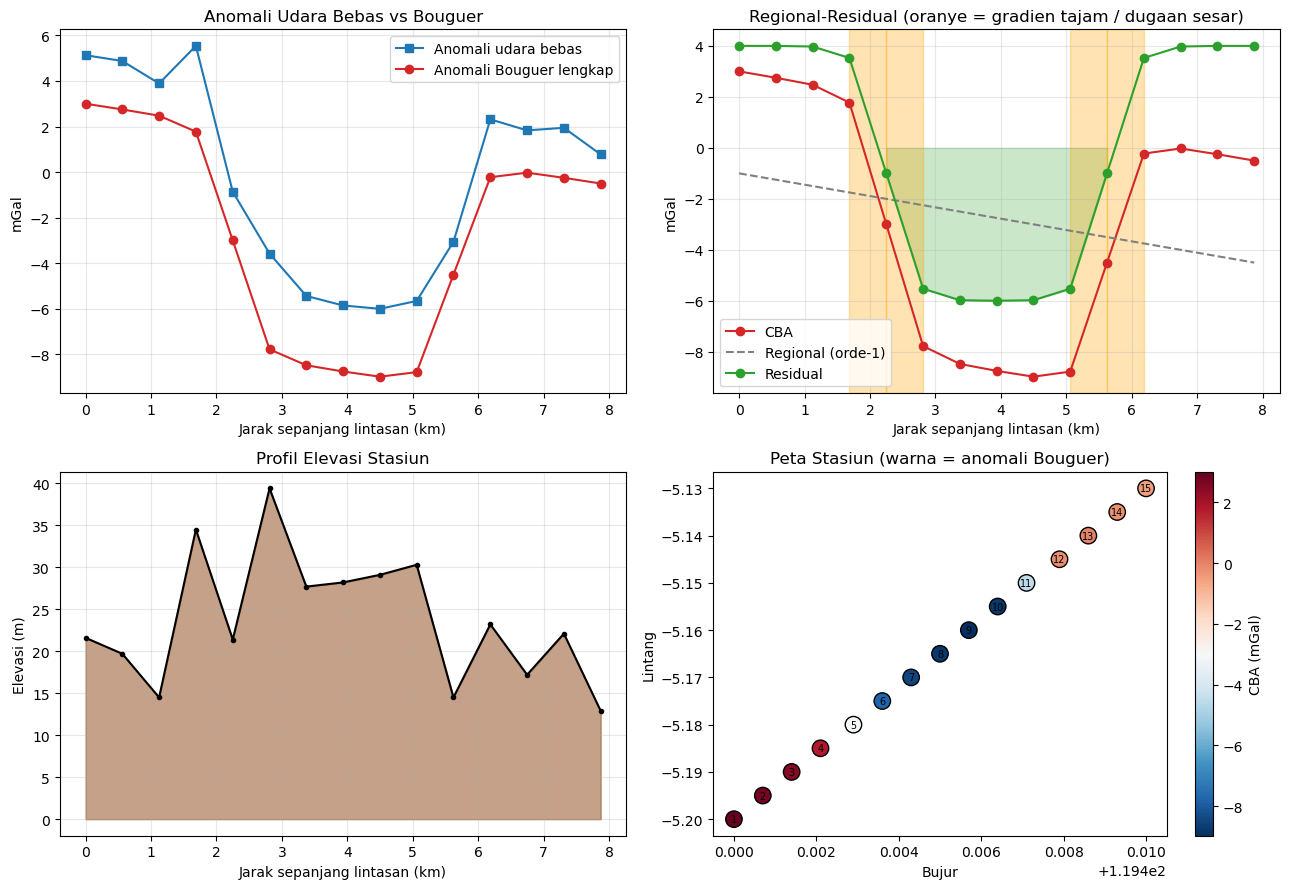

In [5]:
# =====================================================================
# PROMPT 4 : KOREKSI & INTERPRETASI ANOMALI GRAVITASI - CEKUNGAN SEDIMEN
# =====================================================================
print("\n" + "=" * 78)
print("PROMPT 4 : GRAVITASI - ANOMALI BOUGUER & CEKUNGAN SEDIMEN")
print("=" * 78)

# ---------------- INPUT: tabel stasiun ----------------
lat = np.array([-5.2, -5.195, -5.19, -5.185, -5.18, -5.175, -5.17, -5.165, -5.16, -5.155,
                -5.15, -5.145, -5.14, -5.135, -5.13])                            # derajat
lon = np.array([119.4, 119.4007, 119.4014, 119.4021, 119.4029, 119.4036, 119.4043, 119.405,
                119.4057, 119.4064, 119.4071, 119.4079, 119.4086, 119.4093, 119.41])
elev = np.array([21.6, 19.7, 14.5, 34.5, 21.4, 39.4, 27.7, 28.2, 29.1, 30.3, 14.5, 23.2, 17.2, 22.1, 12.9])  # m
waktu = np.array([8.5, 8.86, 9.21, 9.57, 9.93, 10.29, 10.64, 11.0, 11.36, 11.71, 12.07, 12.43, 12.79, 13.14, 13.5])  # jam
bacaan = np.array([2003.571, 2003.819, 2004.354, 1999.749, 1997.309, 1988.963, 1990.635, 1989.988,
                   1989.488, 1989.388, 1996.790, 1999.405, 2000.705, 1999.237, 2000.841])          # mGal (relatif)
tide = np.array([0.013, 0.021, 0.029, 0.036, 0.041, 0.046, 0.049, 0.05, 0.05, 0.048,
                 0.044, 0.039, 0.033, 0.026, 0.017])        # koreksi pasut tiap stasiun (mGal) - dari tabel/Longman
tc = np.array([0.29, 0.08, 0.21, 0.1, 0.26, 0.21, 0.06, 0.26, 0.28, 0.27, 0.18, 0.06, 0.07, 0.28, 0.17])  # koreksi medan (mGal)

# base station (loop tertutup)
t_b0, t_b1 = 8.0, 14.0               # jam awal & akhir
R_b0, R_b1 = 2000.0, 2000.05         # bacaan base awal & akhir (mGal)
tide_b0, tide_b1 = 0.0, 0.040        # koreksi pasut di base
g_abs_base = 978070.0                # gravitasi absolut base (mGal) - ASUMSI contoh, ganti dengan data tie IGSN
rho_red = 2.67                       # g/cm3 - densitas reduksi (rata-rata kerak, asumsi standar; ganti bila ada data)

# ---------------- Koreksi berurutan ----------------
# 1) Pasang surut  2) Apungan (drift)  3) g observasi  4) lintang  5) udara bebas  6) Bouguer  7) medan
Rc = bacaan + tide                                       # 1) koreksi pasut
Rc_b0, Rc_b1 = R_b0 + tide_b0, R_b1 + tide_b1
laju_drift = (Rc_b1 - Rc_b0) / (t_b1 - t_b0)             # mGal/jam
drift = laju_drift * (waktu - t_b0)                      # 2) koreksi apungan
g_obs = g_abs_base + (Rc - Rc_b0) - drift                # 3) g observasi absolut

phi = np.radians(lat)
g_lat = 978032.7 * (1 + 0.0053024 * np.sin(phi)**2 - 0.0000058 * np.sin(2 * phi)**2)   # 4) g normal (GRS67)
FAC = 0.3086 * elev                                      # 5) koreksi udara bebas
BC = 0.04193 * rho_red * elev                            # 6) koreksi Bouguer (lempeng tak hingga)
TC = tc                                                  # 7) koreksi medan (dari input)

FAA = g_obs - g_lat + FAC                                # anomali udara bebas
CBA = g_obs - g_lat + FAC - BC + TC                      # anomali Bouguer lengkap

# ---------------- ARTIFACT 4a ----------------
print("\nDensitas reduksi = %.2f g/cm3 (asumsi rata-rata kerak, bukan hasil pengukuran)." % rho_red)
print("Urutan koreksi: pasut -> apungan -> g_obs -> g_lintang -> udara bebas -> Bouguer -> medan")
print(f"Laju apungan alat = {laju_drift:.4f} mGal/jam")

j = 7   # stasiun contoh
print(f"\n[ARTIFACT 4a] Contoh hitung stasiun ke-{j+1}")
print(f"  Koreksi pasut      : R_c  = {bacaan[j]:.3f} + {tide[j]:.3f} = {Rc[j]:.3f} mGal")
print(f"  Koreksi apungan    : drift = {laju_drift:.4f} x ({waktu[j]:.2f}-{t_b0}) = {drift[j]:.4f} mGal")
print(f"  g observasi        : {g_abs_base:.2f} + ({Rc[j]:.3f}-{Rc_b0:.3f}) - {drift[j]:.4f} = {g_obs[j]:.3f} mGal")
print(f"  g lintang (GRS67)  : 978032.7(1+0.0053024 sin^2 phi - 0.0000058 sin^2 2phi) = {g_lat[j]:.3f} mGal")
print(f"  Udara bebas  (FAC) : 0.3086 x {elev[j]} = {FAC[j]:.3f} mGal")
print(f"  Bouguer      (BC)  : 0.04193 x {rho_red} x {elev[j]} = {BC[j]:.3f} mGal")
print(f"  Koreksi medan (TC) : {TC[j]:.3f} mGal")
print(f"  CBA = g_obs - g_lat + FAC - BC + TC = {CBA[j]:.3f} mGal")

print("\nTabel anomali semua stasiun:")
print(f"{'St':>3} {'lat':>8} {'lon':>9} {'h(m)':>6} {'g_obs':>12} {'FAA':>8} {'CBA':>8}")
for i in range(len(lat)):
    print(f"{i+1:3d} {lat[i]:8.4f} {lon[i]:9.4f} {elev[i]:6.1f} {g_obs[i]:12.3f} {FAA[i]:8.2f} {CBA[i]:8.2f}")

# ---------------- Pemisahan regional-residual (polinomial orde-1 / bidang) ----------------
A = np.column_stack([np.ones(len(lat)), lon - lon.mean(), lat - lat.mean()])
koef, _, _, _ = np.linalg.lstsq(A, CBA, rcond=None)
regional = A @ koef
residual = CBA - regional
print("\nMetode regional-residual yang dipakai: polinomial orde-1 (bidang) dengan kuadrat terkecil.")
print("Alternatif yang diusulkan: upward continuation / filter lolos rendah, polinomial orde-2.")

# ---------------- Gradien antar stasiun (indikasi sesar) ----------------
dx = np.diff(lon) * 111.32 * np.cos(np.radians(lat[:-1]))
dy = np.diff(lat) * 111.32
jarak_km = np.sqrt(dx**2 + dy**2)
gradien = np.diff(CBA) / jarak_km                               # mGal/km
ambang = 5.0                                                    # mGal/km
print("\n[ARTIFACT 4b] Narasi interpretasi anomali")
print(f"- Anomali Bouguer berkisar {CBA.min():.1f} s.d. {CBA.max():.1f} mGal; residual {residual.min():.1f} s.d. {residual.max():.1f} mGal.")
ist_rendah = np.where(residual < -0.5 * np.abs(residual.min()))[0] + 1
print(f"- Residual rendah (dugaan cekungan sedimen, densitas lebih kecil dari sekitarnya): stasiun {[int(v) for v in ist_rendah]}.")
print(f"- Gradien tajam (> {ambang:.0f} mGal/km), dugaan tepi sesar:")
ada_sesar = False
for i in range(len(gradien)):
    if abs(gradien[i]) > ambang:
        ada_sesar = True
        arah = "turun ke arah cekungan" if gradien[i] < 0 else "naik keluar cekungan"
        print(f"    antara stasiun {i+1}-{i+2}: {gradien[i]:6.1f} mGal/km ({arah})")
if not ada_sesar:
    print("    tidak ada gradien yang melewati ambang.")
print("- Kontras densitas negatif (sedimen ~2.0-2.4 g/cm3 vs batuan dasar ~2.67 g/cm3) menjelaskan anomali rendah.")
print("- Peta kontur: bayangkan area biru (rendah) di bagian tengah lintasan, diapit kontur rapat di kedua tepinya.")
corr = np.corrcoef(elev, CBA)[0, 1]
print(f"- Korelasi elevasi vs CBA = {corr:.2f} (mendekati 0 berarti densitas reduksi tidak bias oleh topografi).")
print("Keterbatasan: koreksi medan memakai nilai input (bila kosong dianggap 0 dan jadi sumber galat); model 1 lintasan,")
print("interpretasi non-unik (kompromi densitas-kedalaman).")

# ---------------- Verifikasi: sensitivitas densitas +- 0.1 g/cm3 ----------------
print("\n[Verifikasi: sensitivitas densitas reduksi +-0,1 g/cm3]")
dBC = 0.04193 * 0.1 * elev
print(f"Perubahan BC = 0.04193 x 0.1 x h : {dBC.min():.3f} s.d. {dBC.max():.3f} mGal.")
print("rho +0.1 -> BC bertambah -> CBA berkurang sebesar nilai itu; rho -0.1 -> CBA bertambah.")
print(f"Contoh stasiun {j+1}: CBA = {CBA[j]:.3f} (2.67) | {CBA[j]-dBC[j]:.3f} (2.77) | {CBA[j]+dBC[j]:.3f} (2.57) mGal")
print("Efek kecil dibanding amplitudo anomali cekungan, tetapi bersifat sistematik terhadap elevasi.")

# ---------------- Grafik: profil anomali gravitasi ----------------
dist_km = np.concatenate([[0], np.cumsum(jarak_km)])
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].plot(dist_km, FAA, "s-", color="tab:blue", label="Anomali udara bebas")
ax[0, 0].plot(dist_km, CBA, "o-", color="tab:red", label="Anomali Bouguer lengkap")
ax[0, 0].set_title("Anomali Udara Bebas vs Bouguer")
ax[0, 0].set_ylabel("mGal")
ax[0, 0].legend()

ax[0, 1].plot(dist_km, CBA, "o-", color="tab:red", label="CBA")
ax[0, 1].plot(dist_km, regional, "--", color="gray", label="Regional (orde-1)")
ax[0, 1].plot(dist_km, residual, "o-", color="tab:green", label="Residual")
ax[0, 1].fill_between(dist_km, residual, 0, where=residual < 0, color="tab:green", alpha=0.25)
for i in range(len(gradien)):
    if abs(gradien[i]) > ambang:
        ax[0, 1].axvspan(dist_km[i], dist_km[i + 1], color="orange", alpha=0.3)
ax[0, 1].set_title("Regional-Residual (oranye = gradien tajam / dugaan sesar)")
ax[0, 1].set_ylabel("mGal")
ax[0, 1].legend()

ax[1, 0].fill_between(dist_km, elev, color="saddlebrown", alpha=0.5)
ax[1, 0].plot(dist_km, elev, "k.-")
ax[1, 0].set_title("Profil Elevasi Stasiun")
ax[1, 0].set_ylabel("Elevasi (m)")

sc = ax[1, 1].scatter(lon, lat, c=CBA, cmap="RdBu_r", s=140, edgecolor="k")
for i in range(len(lat)):
    ax[1, 1].annotate(str(i + 1), (lon[i], lat[i]), fontsize=7, ha="center", va="center")
plt.colorbar(sc, ax=ax[1, 1], label="CBA (mGal)")
ax[1, 1].set_xlabel("Bujur")
ax[1, 1].set_ylabel("Lintang")
ax[1, 1].set_title("Peta Stasiun (warna = anomali Bouguer)")
for a in ax.ravel()[:3]:
    a.set_xlabel("Jarak sepanjang lintasan (km)")
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### **Interpretasi Prompt 4**
Anomali Bouguer lengkap berkisar sekitar −9 hingga +3 mGal. Setelah pemisahan regional (bidang orde-1), residual negatif (±−6 mGal) muncul pada stasiun 6–10, konsisten dengan cekungan sedimen berdensitas lebih rendah. Gradien tajam (> 5 mGal/km) di sisi kiri (stasiun 4–6) dan kanan (stasiun 10–12) cekungan diduga sebagai tepi sesar.

Densitas reduksi 2,67 g/cm³ adalah asumsi; perubahan ±0,1 g/cm³ hanya menggeser CBA ±0,05–0,17 mGal, jauh lebih kecil daripada amplitudo cekungan. Interpretasi tetap non-unik (kompromi densitas–kedalaman) dan berasal dari satu lintasan.

---

### **Prompt 5: Interpretasi Anomali Magnetik untuk Eksplorasi Mineral Logam**

**Role:** Kamu adalah seorang geofisikawan eksplorasi mineral yang ahli dalam pengolahan dan interpretasi data magnetik.

**Task:** Jelaskan dan rencanakan pengolahan data medan magnet total hingga anomali magnetik (koreksi harian dan IGRF), lanjutkan dengan reduksi ke kutub, kontinuasi ke atas, dan interpretasi sumber anomali. Narasikan bagaimana pola dipol pada anomali menunjukkan posisi benda termagnetisasi dan bagaimana hasilnya dipakai menentukan target pengeboran.

**Context:** Lokasi berada pada daerah dengan indikasi mineralisasi besi di zona intrusi. Pengguna adalah mahasiswa yang perlu memahami alasan setiap tahap pengolahan.

**Input:** Data medan magnet total (nT) per titik beserta koordinat, waktu, dan data base station harian: [tempel data magnetik]. Sertakan nilai inklinasi dan deklinasi lokasi.

**Constraints:** 
1. Jangan menentukan jenis mineral hanya dari anomali magnetik; nyatakan perlunya data pendukung. 
2. Jelaskan efek inklinasi lokasi terhadap bentuk anomali.
3. Semua nilai parameter harus berasal dari input; bila tidak ada, tanyakan kepada pengguna. 
4. Sebutkan bahwa interpretasi bersifat ambigu (non-unik).

**Output:**  
Dua artifact narasi:  
1. rencana alur pengolahan berurutan dengan tujuan tiap tahap
2. narasi interpretasi anomali dan rekomendasi titik target beserta survei lanjutan (misalnya IP atau pengeboran). Peta anomali cukup digambarkan dengan kata-kata.

**Quality criteria:** Tahapan pengolahan runtut dan beralasan; keterkaitan pola dipol dengan posisi sumber benar; ada pembahasan ambiguitas dan keterbatasan; rekomendasi spesifik dan dapat ditindaklanjuti.

**Optional verification:** Berikan satu skenario alternatif sumber anomali (misalnya struktur dangkal vs. dalam) dan jelaskan bagaimana kontinuasi ke atas dapat membedakannya.



PROMPT 5 : MAGNETIK - ANOMALI, RTP, KONTINUASI KE ATAS

[ARTIFACT 5a] Rencana alur pengolahan
1. Koreksi harian : kurangi variasi base station (interpolasi waktu) -> hilangkan efek medan luar.
2. Koreksi IGRF   : kurangi medan utama bumi (40800 nT) -> diperoleh anomali medan kerak dT.
3. RTP            : (I = -24.0, D = 0.5) pindahkan puncak anomali ke atas sumber; filter dibatasi pada |I| >= 20 deg.
4. Kontinuasi ke atas (10 m, 20 m): redam sumber dangkal, pertegas sumber dalam.
5. Interpretasi   : posisi, kedalaman relatif, dan ambiguitas sumber.

[ARTIFACT 5b] Narasi interpretasi anomali
- Anomali dT: maks 185.3 nT di (x=50, y=40) m; min -145.3 nT di (x=50, y=50) m.
- Pola dipol: puncak positif dan lembah negatif berpasangan; lembah berada di sisi utara puncak.
  Pada inklinasi -24 deg (rendah), bentuk anomali memanjang/asimetris dan puncaknya bergeser dari sumber.
- Setelah RTP puncak berada di (x=50, y=50) m = dugaan posisi horizontal sumber.
- Sisa amplitudo maks setelah kontinu

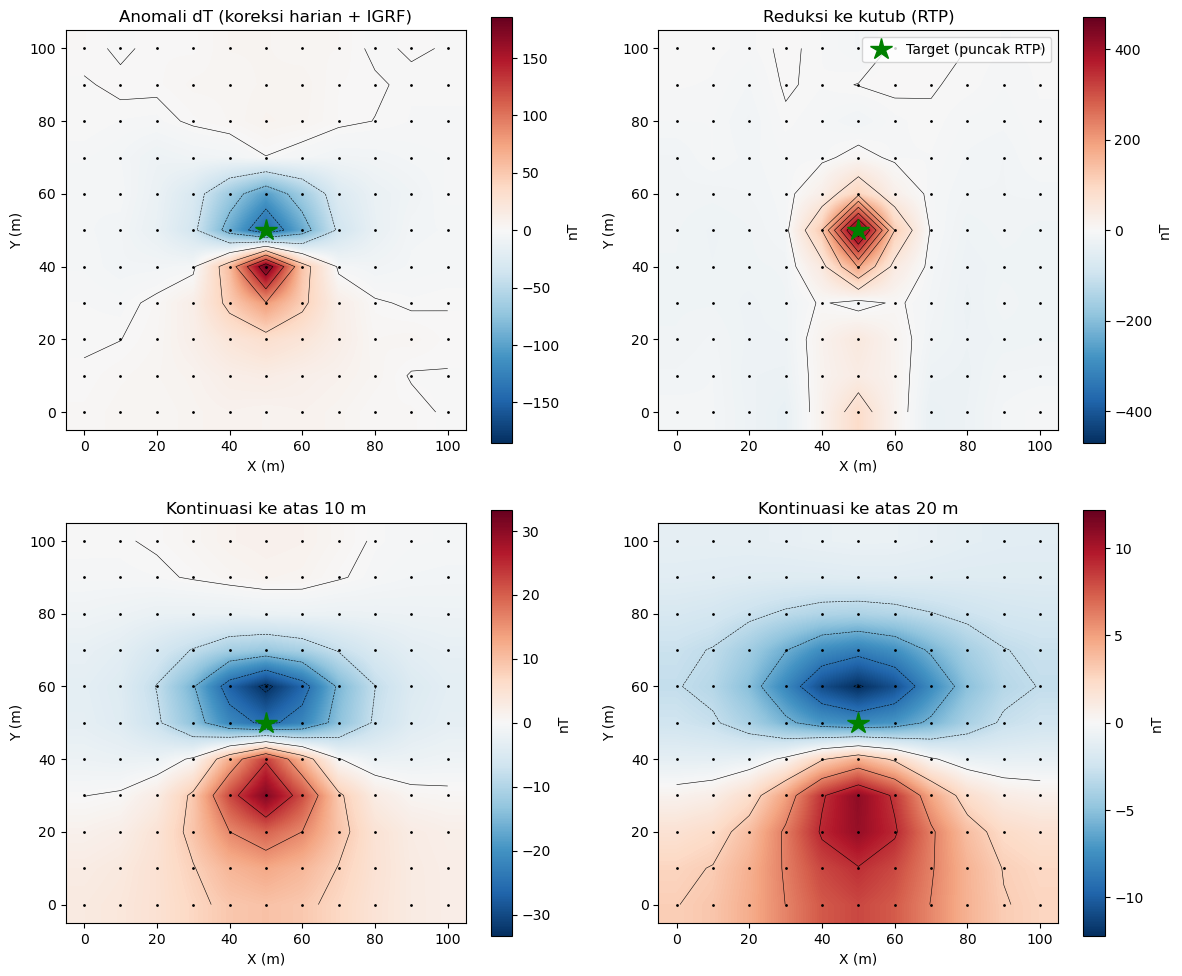

In [7]:
# =====================================================================
# PROMPT 5 : ANOMALI MAGNETIK - EKSPLORASI MINERAL LOGAM
# =====================================================================
print("\n" + "=" * 78)
print("PROMPT 5 : MAGNETIK - ANOMALI, RTP, KONTINUASI KE ATAS")
print("=" * 78)

# ---------------- INPUT ----------------
inklinasi = -24.0       # derajat (dari IGRF lokasi - ganti dengan nilai kalkulator IGRF/NOAA)
deklinasi = 0.5         # derajat
F_igrf = 40800.0        # nT (IGRF lokasi, dari kalkulator IGRF)
spasi = 10.0            # m
nx = ny = 11

# --- DATA CONTOH: dipol sintetik + variasi harian (GANTI dengan data lapangan) ---
xs = np.arange(nx) * spasi
ys = np.arange(ny) * spasi
X, Y = np.meshgrid(xs, ys)
Ir, Dr = np.radians(inklinasi), np.radians(deklinasi)
Fh = np.array([np.cos(Ir) * np.sin(Dr), np.cos(Ir) * np.cos(Dr), -np.sin(Ir)])   # (timur, utara, atas)
rx, ry, rz = X - 50.0, Y - 50.0, 0.0 + 12.0                                    # sumber di (50,50), kedalaman 12 m
r = np.sqrt(rx**2 + ry**2 + rz**2)
mr = Fh[0] * rx + Fh[1] * ry + Fh[2] * (-rz)
dT_sumber = 100.0 * 5000.0 * (3 * mr * mr / r**2 - 1) / r**3                     # nT (sumber induksi)
t_ukur = np.linspace(9.0, 12.0, nx * ny).reshape(ny, nx)                         # jam
t_base = np.array([8.5, 9.5, 10.5, 11.5, 12.5])                                  # jam
v_base = np.array([40800.0, 40806.0, 40815.0, 40810.0, 40801.0])                 # nT bacaan base
T_total = F_igrf + dT_sumber + (np.interp(t_ukur, t_base, v_base) - v_base[0]) + rng.normal(0, 1.0, (ny, nx))

# ---------------- Tahap 1: koreksi harian & IGRF ----------------
variasi_harian = np.interp(t_ukur, t_base, v_base) - v_base[0]      # variasi relatif terhadap bacaan awal
dT = T_total - variasi_harian - F_igrf                              # anomali magnetik (nT)

# ---------------- Tahap 2: reduksi ke kutub (RTP, domain Fourier) ----------------
pad = 10
dT_pad = np.pad(dT - dT.mean(), pad, mode="reflect")
ny2, nx2 = dT_pad.shape
kx = 2 * np.pi * np.fft.fftfreq(nx2, d=spasi)
ky = 2 * np.pi * np.fft.fftfreq(ny2, d=spasi)
KX, KY = np.meshgrid(kx, ky)
kk = np.sqrt(KX**2 + KY**2)
kk[0, 0] = 1e-12
theta = np.arctan2(KX, KY)                                          # sudut dari utara
# Catatan: pada inklinasi rendah RTP tidak stabil -> inklinasi filter dibatasi minimal 20 derajat
I_f = np.sign(inklinasi) * max(abs(inklinasi), 20.0)
Ifr = np.radians(I_f)
Dfr = Dr
# (tanda imajiner negatif karena konvensi FFT numpy exp(-ikx))
rtp_filter = 1.0 / ((np.sin(Ifr) - 1j * np.cos(Ifr) * np.cos(Dfr - theta)) ** 2)
rtp_filter = np.where(np.abs(rtp_filter) > 5, 5 * rtp_filter / np.abs(rtp_filter), rtp_filter)  # redam amplitudo
spek = np.fft.fft2(dT_pad)
rtp = np.real(np.fft.ifft2(spek * rtp_filter))[pad:-pad, pad:-pad]

# ---------------- Tahap 3: kontinuasi ke atas ----------------
naik = {}
for h_naik in [10.0, 20.0]:
    naik[h_naik] = np.real(np.fft.ifft2(spek * np.exp(-h_naik * kk)))[pad:-pad, pad:-pad]

# ---------------- ARTIFACT 5a : rencana alur ----------------
print("\n[ARTIFACT 5a] Rencana alur pengolahan")
print("1. Koreksi harian : kurangi variasi base station (interpolasi waktu) -> hilangkan efek medan luar.")
print("2. Koreksi IGRF   : kurangi medan utama bumi (%.0f nT) -> diperoleh anomali medan kerak dT." % F_igrf)
print(f"3. RTP            : (I = {inklinasi}, D = {deklinasi}) pindahkan puncak anomali ke atas sumber; "
      f"filter dibatasi pada |I| >= 20 deg.")
print("4. Kontinuasi ke atas (10 m, 20 m): redam sumber dangkal, pertegas sumber dalam.")
print("5. Interpretasi   : posisi, kedalaman relatif, dan ambiguitas sumber.")

# ---------------- ARTIFACT 5b : interpretasi ----------------
imax = np.unravel_index(np.argmax(dT), dT.shape)
imin = np.unravel_index(np.argmin(dT), dT.shape)
irtp = np.unravel_index(np.argmax(rtp), rtp.shape)
print("\n[ARTIFACT 5b] Narasi interpretasi anomali")
print(f"- Anomali dT: maks {dT.max():.1f} nT di (x={xs[imax[1]]:.0f}, y={ys[imax[0]]:.0f}) m; "
      f"min {dT.min():.1f} nT di (x={xs[imin[1]]:.0f}, y={ys[imin[0]]:.0f}) m.")
arah_ns = "selatan" if ys[imin[0]] < ys[imax[0]] else "utara"
print(f"- Pola dipol: puncak positif dan lembah negatif berpasangan; lembah berada di sisi {arah_ns} puncak.")
print("  Pada inklinasi %.0f deg (rendah), bentuk anomali memanjang/asimetris dan puncaknya bergeser dari sumber." % inklinasi)
print(f"- Setelah RTP puncak berada di (x={xs[irtp[1]]:.0f}, y={ys[irtp[0]]:.0f}) m = dugaan posisi horizontal sumber.")

rasio10 = naik[10.0].max() / dT.max()
rasio20 = naik[20.0].max() / dT.max()
print(f"- Sisa amplitudo maks setelah kontinuasi: 10 m = {rasio10*100:.0f} %, 20 m = {rasio20*100:.0f} %.")
if rasio20 > 0.35:
    print("  Redaman lambat -> sumber relatif dalam/besar.")
else:
    print("  Redaman cepat -> sumber relatif dangkal/kecil.")
print(f"- Rekomendasi titik target: sekitar (x={xs[irtp[1]]:.0f}, y={ys[irtp[0]]:.0f}) m; "
      "survei lanjutan IP/resistivitas dan pemodelan 2D/3D sebelum pengeboran uji.")
print("Batasan: anomali magnetik TIDAK menentukan jenis mineral (magnetit/pirotit/dsb); butuh data geologi, suseptibilitas, dan IP/bor.")
print("Interpretasi bersifat ambigu (non-unik): kombinasi kedalaman, ukuran, dan suseptibilitas dapat memberi anomali serupa.")

print("\n[Verifikasi: skenario alternatif]")
print("Skenario A: sumber dangkal kecil -> amplitudo turun cepat saat kontinuasi ke atas.")
print("Skenario B: sumber dalam besar  -> amplitudo bertahan, bentuk makin halus.")
print(f"Hasil data: rasio sisa 20 m = {rasio20:.2f} -> mendukung skenario {'B' if rasio20 > 0.35 else 'A'}.")

# ---------------- Grafik: peta anomali magnetik ----------------
peta = [("Anomali dT (koreksi harian + IGRF)", dT),
        ("Reduksi ke kutub (RTP)", rtp),
        ("Kontinuasi ke atas 10 m", naik[10.0]),
        ("Kontinuasi ke atas 20 m", naik[20.0])]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (judul, grid) in zip(axes.ravel(), peta):
    vm = np.abs(grid).max()
    im = ax.imshow(grid, origin="lower", extent=[-spasi / 2, xs[-1] + spasi / 2, -spasi / 2, ys[-1] + spasi / 2],
                   cmap="RdBu_r", vmin=-vm, vmax=vm, interpolation="bilinear")
    ax.contour(X, Y, grid, levels=8, colors="k", linewidths=0.4)
    ax.plot(X.ravel(), Y.ravel(), "k.", ms=2)
    ax.plot(xs[irtp[1]], ys[irtp[0]], "g*", ms=16, label="Target (puncak RTP)")
    plt.colorbar(im, ax=ax, label="nT")
    ax.set_title(judul)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
axes[0, 1].legend(loc="upper right")
plt.tight_layout()
plt.show()

#### **Interpretasi Prompt 5**
Pada peta dT terlihat pola dipol: puncak positif (±+188 nT) di selatan dan lembah negatif (±−147 nT) di utara, khas inklinasi rendah (−24°). Setelah RTP, anomali menjadi satu puncak tunggal tepat di atas sumber, sekitar (x = 50 m, y = 50 m), yang menjadi titik target.

Kontinuasi ke atas meredam amplitudo dengan cepat (sisa ±16 % pada 10 m dan ±6 % pada 20 m), menandakan sumber relatif dangkal. Anomali magnetik tidak dapat menentukan jenis mineral; diperlukan data pendukung seperti IP, geologi, dan pengeboran, dan interpretasi tetap bersifat ambigu.

---